## C1 - WEEK 4

- Adrià Cantarero Carreras  (1809773@uab.cat)
- Ivan Martin Campoy (1673246@uab.cat)
- Irene Pumares Benaiges (1810704@uab.cat)
- Lavish Ramchandani (1691238@uab.cat)

In [13]:
import sys
sys.path.append("..")  # repo root, for utils/
#needed libraries

import os
import re
import cv2
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

## Common pipeline (from Week 3)

Every photo goes through the same steps before the local descriptors:

1. Denoising (Week 3, Task 1): impulse / additive noise detector, median 3x3 only on the photos detected as noisy.
2. Painting detection (Week 3, Task 3): wall colour model in Lab (Week 2 method C) + hole filling + connected components, now with any number of paintings per photo, plus three small new steps explained in that section.
3. Crop the bounding box of every painting from the denoised photo.
4. Local descriptors + matching (Tasks 1-2, next sections) give a score per BBDD image for every crop.
5. Output: for every photo, one list per painting with the top-10 BBDD ids, or `[-1]` if the painting is unknown.

Only the selected configuration of every Week 3 step is copied here.

### Data

In [14]:
#paths and results folder
bbdd_path = "./data/BBDD"
qsd1_path = "./data/qsd1_w4"
results_dir = "./results"
os.makedirs(results_dir, exist_ok=True)

def read_image(img_path):
    image = cv2.imread(img_path)
    if image is None:
        raise IOError(f"Could not read {img_path}")
    return image

#sort files in natural order
def return_number(string):
    return [int(text) if text.isdigit() else text.lower() for text in re.split(r'(\d+)', string)]

def load_query_set(folder):
    files = sorted([f for f in os.listdir(folder) if f.lower().endswith(".jpg")], key=return_number)
    return files, [read_image(os.path.join(folder, f)) for f in files]

def load_pickle(path):
    #None if the file is not in the dataset
    if not os.path.exists(path):
        return None
    with open(path, "rb") as f:
        return pickle.load(f)

def as_id_list(g):
    #one ground truth entry -> list of int bbdd ids (one per painting, -1 = not in the museum)
    return [int(x) for x in g] if isinstance(g, (list, tuple, np.ndarray)) else [int(g)]

#type of every photo (only used to analyse the results, never to retrieve)
def aug_type(a):
    a = str(a).lower()
    if "noise" in a:
        return "noise"
    if "color" in a or "hue" in a:
        return "color"
    return "none"

#museum
bbdd_files, bbdd_imgs = load_query_set(bbdd_path)
bbdd_ids = np.array([int(re.findall(r"\d+", f)[-1]) for f in bbdd_files]) #bbdd_00012.jpg -> 12
bbdd_index = {b: i for i, b in enumerate(bbdd_ids)} #bbdd id -> position in bbdd_imgs

#QSD1-W4 photos and ground truth (correct answers): one bbdd id per painting, left to right (-1 = painting not in the museum)
qsd1_files, qsd1_imgs = load_query_set(qsd1_path)
qsd1_gt = [as_id_list(g) for g in load_pickle(os.path.join(qsd1_path, "gt_corresps.pkl"))]
qsd1_n_paintings = np.array([len(g) for g in qsd1_gt])

#optional files (only to analyse the results)
qsd1_augs = load_pickle(os.path.join(qsd1_path, "augmentations.pkl"))
qsd1_type = np.array([aug_type(a) for a in qsd1_augs]) if qsd1_augs is not None else None
mask_paths = [os.path.join(qsd1_path, os.path.splitext(f)[0] + ".png") for f in qsd1_files]
qsd1_gt_masks = [cv2.imread(p, cv2.IMREAD_GRAYSCALE) > 0 for p in mask_paths] if all(map(os.path.exists, mask_paths)) else None

n_unknown = sum(g.count(-1) for g in qsd1_gt)
print(f"BBDD: {len(bbdd_imgs)} images")
print(f"QSD1-W4: {len(qsd1_imgs)} photos, {qsd1_n_paintings.sum()} paintings "
      f"({np.sum(qsd1_n_paintings == 2)} photos with two), {n_unknown} paintings not in the museum")
if qsd1_type is not None:
    print("photo types:", pd.Series(qsd1_type).value_counts().to_dict())
print("Ground truth masks available:", qsd1_gt_masks is not None)

BBDD: 287 images
QSD1-W4: 30 photos, 39 paintings (9 photos with two), 10 paintings not in the museum
photo types: {'color': 12, 'none': 9, 'noise': 9}
Ground truth masks available: True


### Denoising (Week 3, Task 1)

Copied without changes: the thresholds were chosen on QSD1-W3 and the filter is the best one of the Week 3 comparison (median 3x3, best PSNR and SSIM). The median filter is only applied to the photos detected as noisy.

In [15]:
# Additive noise (a small random value added to each pixel)

LAPLACIAN_DIFF = np.array([[1, -2, 1],
                           [-2, 4, -2],
                           [1, -2, 1]], dtype=np.float64)

def additive_noise(img):
    sigmas = []
    for c in range(img.shape[2]):
        residual = cv2.filter2D(img[..., c].astype(np.float64), -1, LAPLACIAN_DIFF)[1:-1, 1:-1]   #drop the border (padding)
        sigmas.append(np.median(np.abs(residual)) / (0.6745 * 6))
    return np.mean(sigmas)

# Impulse noise (a pixel is replaced by a random value)

T_ISOLATED = 30 #grey levels a pixel must stand out from all its neighbours (~10% of the 0-255 range)
RING = np.ones((3, 3), np.uint8)
RING[1, 1] = 0 #structuring element = the 8 neighbours, without the centre pixel

def impulsive_noise(img, t=T_ISOLATED):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.int16)
    neigh_max = cv2.dilate(gray, RING) #max of the 8 neighbours
    neigh_min = cv2.erode(gray, RING) #min of the 8 neighbours
    return np.mean((gray > neigh_max + t) | (gray < neigh_min - t))

ISOLATED_THRESHOLD = 0.01 #fraction of isolated pixels
SIGMA_THRESHOLD = 8.0 #estimated noise std

def is_noisy(img):
    if impulsive_noise(img) > ISOLATED_THRESHOLD:
        return True
    if additive_noise(img) > SIGMA_THRESHOLD:
        return True
    return False

def denoise(img):
    #median 3x3 (best filter of Week 3) only if the photo is detected as noisy
    return cv2.medianBlur(img, 3) if is_noisy(img) else img

In [16]:
qsd1_detected = np.array([is_noisy(img) for img in qsd1_imgs])
qsd1_denoised = [denoise(img) for img in qsd1_imgs]
print("Detected as noisy:", [qsd1_files[i] for i in np.where(qsd1_detected)[0]])

#check with the real labels (only here, never used to decide)
if qsd1_type is not None:
    really_noisy = qsd1_type == "noise"
    print(f"Correctly detected: {np.sum(qsd1_detected & really_noisy)}/{really_noisy.sum()}")
    print(f"False positives: {np.sum(qsd1_detected & ~really_noisy)}/{np.sum(~really_noisy)}")

Detected as noisy: ['00003.jpg', '00008.jpg', '00012.jpg', '00017.jpg', '00019.jpg', '00022.jpg', '00023.jpg', '00024.jpg', '00025.jpg']
Correctly detected: 9/9
False positives: 0/21


### Painting detection (Week 3, Task 3 + new steps)

Same method as Week 3: we learn the wall colour from the outer 3% of the photo, every pixel with a colour different enough from the wall is painting, then we fill the holes and keep the big connected components (at least 5% of the photo).

With the Week 3 method, 4 of the 30 photos of QSD1-W4 have a wrong number of paintings. The new steps (marked with `NEW` in the code) try to fix them:

1. **Any number of paintings** (`MAX_PAINTINGS = None`). Week 3 kept at most 2. On QSD1-W4 both options give the same masks, but the test set may have more.
2. **Opening** (morphology, opening and closing lesson). In 00020 the two paintings are joined by a thin band of pixels between the frames, so they are found as one. The opening removes everything thinner than a small square and keeps the big shapes, so the two paintings are separated.
3. **Join pieces of the same painting.** In 00026 some parts of the painting have the same colour as the wall, so the painting is cut in two pieces. If a piece is mostly inside the box of a bigger piece, we join them.
4. **Order of the paintings** (`ORDER = "auto"`). In Week 3 the paintings were always side by side, so we sorted them by their left edge. When one painting is above the other (00006, 00020, 00028) that order is random, so we sort them from top to bottom.

Not solved: a white drawing on a white wall (right painting of 00016, top painting of 00028). Only its frame has a different colour, the same problem as 00002 in Week 3.

In [17]:
from functools import cmp_to_key

BORDER_RATIO = 0.03 #outer 3% of each side is assumed to be wall
W2_PARAMS = dict(tau=10, tau2=1.5, rho=0.6) #best Week 2 configuration (Lab, method C)
MIN_AREA = 0.05 #a painting covers at least 5% of the photo
MAX_PAINTINGS = None #NEW: None = any number of paintings (Week 3: 2)
OPEN_FRAC = 0.02 #NEW: size of the opening square, 2% of the smallest side of the photo (0 = no opening)
MERGE_OVERLAP = 0.5 #NEW: join a piece if half of its box is inside a bigger piece (None = do not join)
ORDER = "auto" #NEW: "left-right" (Week 3) or "auto" (top to bottom when one painting is above the other)

def border_region(shape, border_ratio=BORDER_RATIO):
    #boolean map of the outer strip of the photo
    h, w = shape[:2]
    bh, bw = max(1, round(border_ratio * h)), max(1, round(border_ratio * w))
    region = np.zeros((h, w), dtype=bool)
    region[:bh, :] = True
    region[-bh:, :] = True
    region[:, :bw] = True
    region[:, -bw:] = True
    return region

def wall_colour_mask(image, tau=10, tau2=1.5, rho=0.6):
    #Week 2 method C in Lab: True = painting
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB).astype(np.float32)
    chroma, luma = lab[..., 1:], lab[..., 0]
    border = border_region(luma.shape)
    dist = np.sqrt(np.sum((chroma - np.median(chroma[border], axis=0)) ** 2, axis=-1)) #colour distance to the wall
    ratio = luma / (np.median(luma[border]) + 1e-6) #light relative to the wall
    return (dist > tau) | ((ratio < rho) & (dist > tau2))

def fill_holes(mask):
    #flood the background from the border; whatever background is not reached is a hole
    padded = np.pad(mask.astype(np.uint8), 1, constant_values=0)
    ff_mask = np.zeros((padded.shape[0] + 2, padded.shape[1] + 2), np.uint8)
    cv2.floodFill(padded, ff_mask, (0, 0), 1)
    return mask.astype(bool) | (padded[1:-1, 1:-1] == 0)

def split_bridges(mask, open_frac=OPEN_FRAC):
    #NEW: opening = erosion + dilation with a square
    #why: two paintings can be joined by a thin band of pixels (a shadow between the frames) and then they count as one painting
    #the erosion deletes everything thinner than the square (the band), the dilation gives the paintings back their size,
    #and the band does not come back because it was already deleted
    s = max(3, int(round(open_frac * min(mask.shape))))
    se = cv2.getStructuringElement(cv2.MORPH_RECT, (s, s))
    return cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_OPEN, se).astype(bool)

def inside_fraction(a, b):
    #NEW: how much of box a = (x0, y0, x1, y1) is inside box b (0 = nothing, 1 = all)
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    return ix * iy / ((a[2] - a[0]) * (a[3] - a[1]))

def union_box(a, b):
    #NEW: smallest box that contains both boxes
    return (min(a[0], b[0]), min(a[1], b[1]), max(a[2], b[2]), max(a[3], b[3]))

def reading_order(a, b, order=ORDER):
    #NEW: which of two paintings goes first in the result
    #why: with one painting above the other, the left edge gives a random order (both start almost at the same x)
    #"auto": if the two paintings share most of their horizontal range (one is above the other), the top one goes first
    #otherwise, the left one goes first (as in Week 3)
    if order == "auto":
        x_overlap = min(a[2], b[2]) - max(a[0], b[0])
        if x_overlap > 0.5 * min(a[2] - a[0], b[2] - b[0]):
            return a[1] - b[1]
    return a[0] - b[0]

def painting_regions(mask, min_area=MIN_AREA, max_paintings=MAX_PAINTINGS, merge_overlap=MERGE_OVERLAP, order=ORDER):
    #-> list of boolean masks, one per painting, in order (see reading_order)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    boxes = [(x, y, x + w, y + h) for x, y, w, h in stats[:, :4]]
    #NEW: join pieces of the same painting
    #why: if part of a painting has the same colour as the wall, the painting is cut into pieces
    #we go from the biggest piece to the smallest; a piece that is mostly inside the box of a bigger one is joined to it
    #two different paintings never overlap like that
    groups = [] #[box, area, labels], biggest component first
    for label in sorted(range(1, n), key=lambda l: -stats[l, cv2.CC_STAT_AREA]):
        area = stats[label, cv2.CC_STAT_AREA]
        target = None
        if merge_overlap is not None:
            target = next((g for g in groups if inside_fraction(boxes[label], g[0]) >= merge_overlap), None)
        if target is None:
            groups.append([boxes[label], area, [label]])
        else:
            target[0], target[1] = union_box(target[0], boxes[label]), target[1] + area
            target[2].append(label)
    groups = [g for g in sorted(groups, key=lambda g: -g[1]) if g[1] >= min_area * mask.size]
    if max_paintings is not None:
        groups = groups[:max_paintings]
    groups.sort(key=cmp_to_key(lambda g1, g2: reading_order(g1[0], g2[0], order)))
    return [np.isin(labels, g[2]) for g in groups]

def segment_paintings(image, min_area=MIN_AREA, max_paintings=MAX_PAINTINGS,
                      open_frac=OPEN_FRAC, merge_overlap=MERGE_OVERLAP, order=ORDER):
    #-> list of boolean masks, one per painting, in order (see reading_order)
    mask = fill_holes(wall_colour_mask(image, **W2_PARAMS))
    if open_frac:
        mask = split_bridges(mask, open_frac)
    regions = painting_regions(mask, min_area, max_paintings, merge_overlap, order)
    return regions if regions else [np.ones(image.shape[:2], dtype=bool)] #nothing found: the whole photo

def union(regions):
    #one mask with all the paintings of the photo
    return np.any(regions, axis=0)

def bbox_crop(image, region):
    ys, xs = np.nonzero(region)
    return image[ys.min():ys.max() + 1, xs.min():xs.max() + 1]

def draw_regions(image, regions, gt=None):
    #detected paintings: light colour + outline + order number; correct mask outline in green
    colours = [(255, 120, 0), (0, 120, 255), (170, 0, 255), (255, 0, 120)]
    out = cv2.cvtColor(image, cv2.COLOR_BGR2RGB).copy()
    thick = max(2, image.shape[1] // 250)
    for k, r in enumerate(regions):
        c = colours[k % len(colours)]
        out[r] = (0.75 * out[r] + 0.25 * np.array(c)).astype(np.uint8)
        cnts, _ = cv2.findContours(r.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(out, cnts, -1, c, thick)
        ys, xs = np.nonzero(r)
        cv2.putText(out, str(k + 1), (int(xs.mean()), int(ys.mean())), cv2.FONT_HERSHEY_SIMPLEX,
                    image.shape[1] / 300, c, 3 * thick)
    if gt is not None:
        cnts, _ = cv2.findContours(gt.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(out, cnts, -1, (0, 255, 0), thick)
    return out

In [18]:
EPS = 1e-10

def mask_prf(pred, gt):
    tp = np.count_nonzero(pred & gt)
    fp = np.count_nonzero(pred & ~gt)
    fn = np.count_nonzero(~pred & gt)
    p, r = tp / (tp + fp + EPS), tp / (tp + fn + EPS)
    return p, r, 2 * p * r / (p + r + EPS)

def evaluate_segmentation(regions):
    #right number of paintings per photo and, if the correct masks are available, pixel precision / recall / F1
    count_ok = np.array([len(r) == n for r, n in zip(regions, qsd1_n_paintings)])
    out = {"Right count": count_ok.sum()}
    if qsd1_gt_masks is not None:
        p, r, f1 = np.mean([mask_prf(union(rr), g) for rr, g in zip(regions, qsd1_gt_masks)], axis=0)
        out.update({"Precision": p, "Recall": r, "F1": f1})
    return out

#one fix at a time, then both
SEG_CONFIGS = {
    "W3 method": dict(open_frac=0, merge_overlap=None),
    "+ opening": dict(open_frac=OPEN_FRAC, merge_overlap=None),
    "+ merge fragments": dict(open_frac=0, merge_overlap=MERGE_OVERLAP),
    "+ opening + merge": dict(open_frac=OPEN_FRAC, merge_overlap=MERGE_OVERLAP),
}
seg_runs, rows = {}, []
for name, params in SEG_CONFIGS.items():
    seg_runs[name] = [segment_paintings(img, **params) for img in qsd1_denoised]
    rows.append({"Method": name, **evaluate_segmentation(seg_runs[name])})
df_seg = pd.DataFrame(rows)
df_seg.to_csv(os.path.join(results_dir, "pipeline_segmentation.csv"), index=False)
display(df_seg.round(4))

#sensitivity to the size of the opening (with merge)
sens = {f: evaluate_segmentation([segment_paintings(img, open_frac=f) for img in qsd1_denoised]) for f in [0.01, 0.02, 0.03, 0.05]}
display(pd.DataFrame(sens).T.rename_axis("open frac").round(4))

#selected: best number of right counts, then best F1 (if the correct masks are available)
SEG_BEST = df_seg.sort_values(["Right count"] + (["F1"] if "F1" in df_seg else []), ascending=False).iloc[0]["Method"]
SEG_PARAMS = SEG_CONFIGS[SEG_BEST]
qsd1_regions = seg_runs[SEG_BEST]
print("Selected:", SEG_BEST, SEG_PARAMS)
wrong_count = [(qsd1_files[i], len(r), int(n)) for i, (r, n) in enumerate(zip(qsd1_regions, qsd1_n_paintings)) if len(r) != n]
print("photos with a wrong number of paintings (file, found, correct):", wrong_count)

,Method,Right count,Precision,Recall,F1
0,W3 method,26,0.9463,0.8884,0.8976
1,+ opening,27,0.9489,0.9086,0.9159
2,+ merge fragments,27,0.9440,0.8988,0.9057
3,+ opening + merge,27,0.9505,0.8795,0.8902


,Right count,Precision,Recall,F1
open frac,,,,
0.01,27.0,0.9507,0.8839,0.8947
0.02,27.0,0.9505,0.8795,0.8902
0.03,27.0,0.9497,0.9090,0.9168
0.05,27.0,0.9514,0.9060,0.9149


Selected: + opening {'open_frac': 0.02, 'merge_overlap': None}
photos with a wrong number of paintings (file, found, correct): [('00016.jpg', 1, 2), ('00020.jpg', 1, 2), ('00028.jpg', 1, 2)]


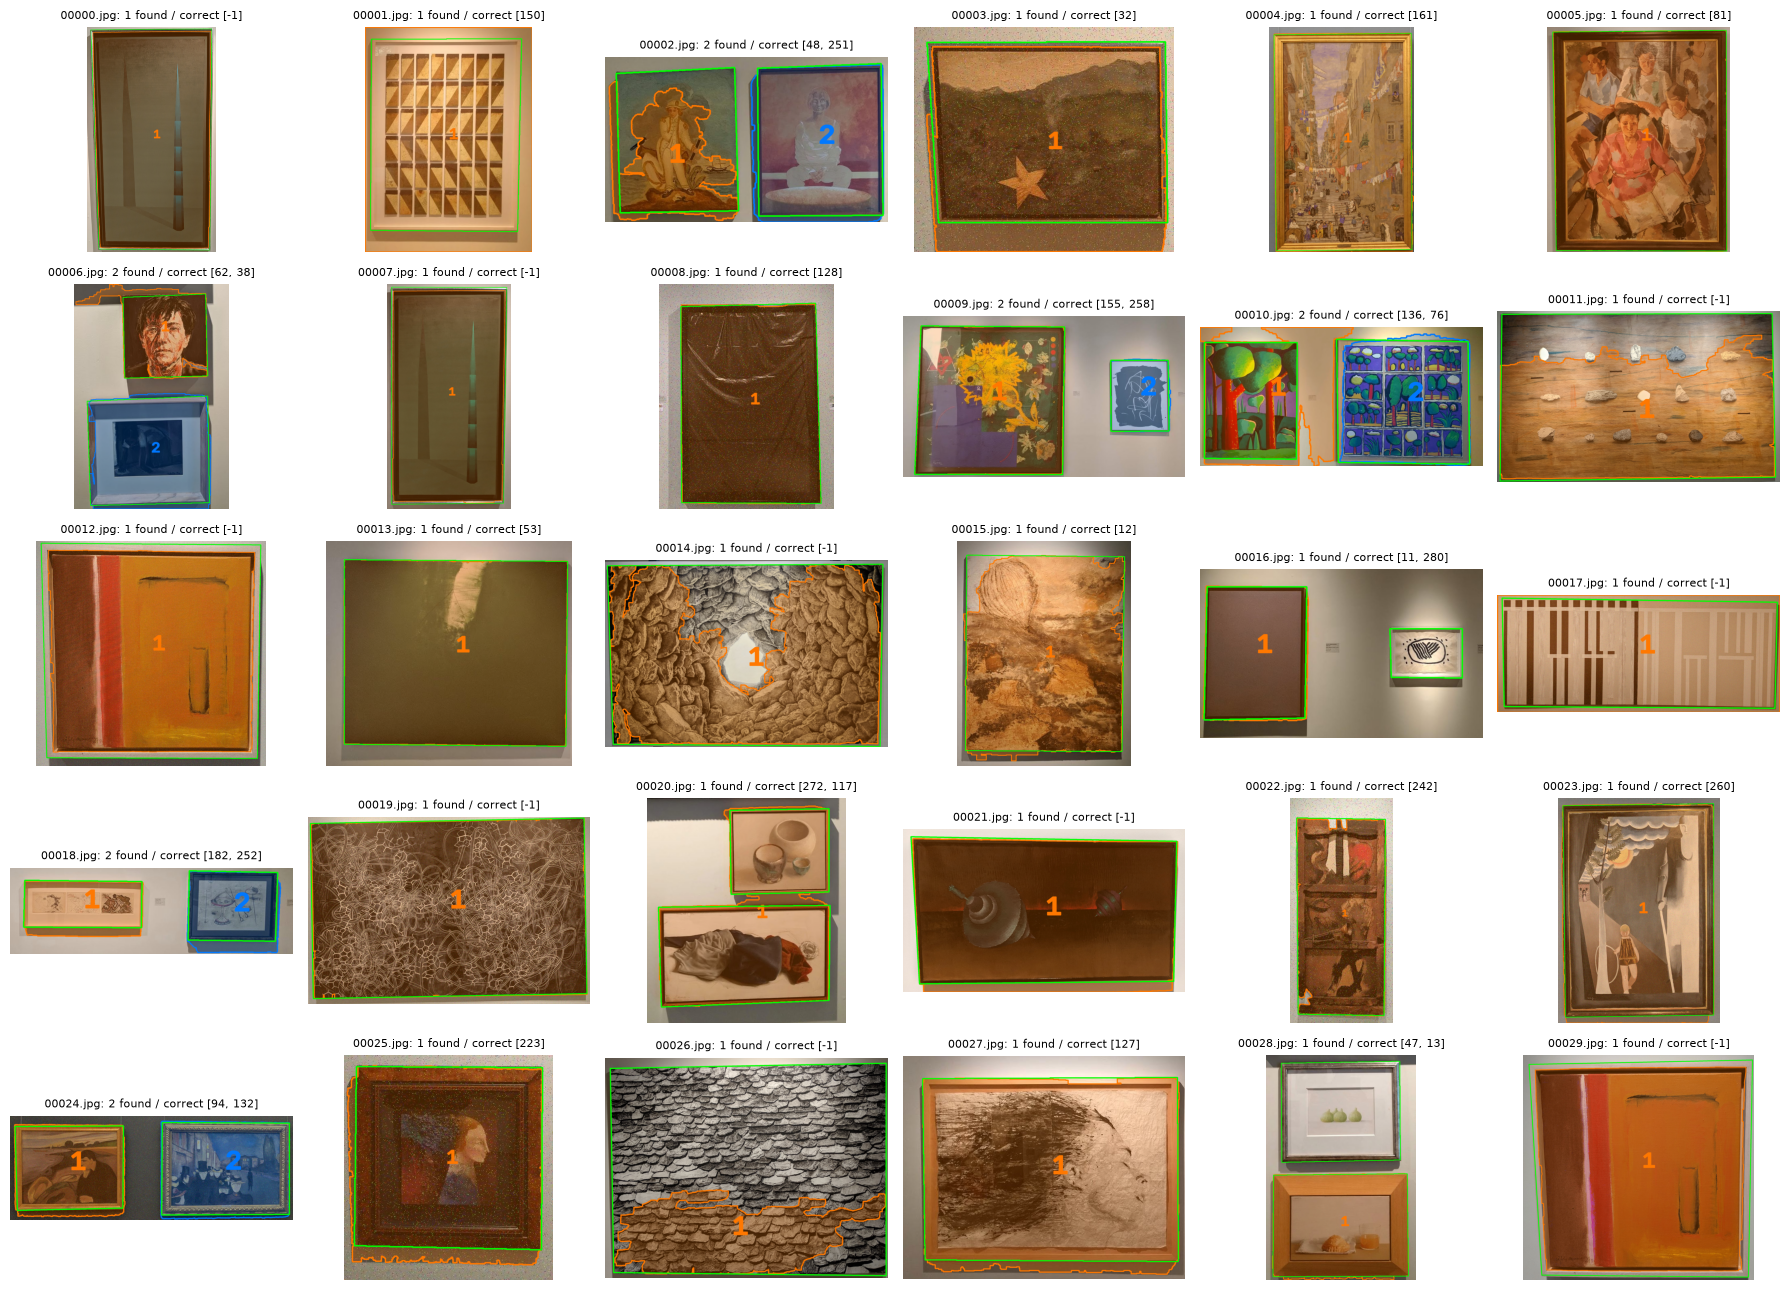

In [19]:
#visual check: every QSD1-W4 photo with its detected paintings (number = our order, correct mask outline in green)
n_cols = 6
n_rows = int(np.ceil(len(qsd1_files) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 2.6 * n_rows), squeeze=False)
for i, ax in enumerate(axes.ravel()):
    ax.axis("off")
    if i < len(qsd1_files):
        gt = qsd1_gt_masks[i] if qsd1_gt_masks is not None else None
        ax.imshow(draw_regions(qsd1_imgs[i], qsd1_regions[i], gt))
        ax.set_title(f"{qsd1_files[i]}: {len(qsd1_regions[i])} found / correct {qsd1_gt[i]}", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(results_dir, "pipeline_qsd1_regions.png"), dpi=90, bbox_inches="tight")
plt.show()

#### Check: in which order are the paintings in `gt_corresps.pkl`?

`gt_corresps.pkl` gives, for every photo, the correct BBDD id of every painting, in a fixed order. The evaluation compares our first painting with the first correct one, and our second with the second, so if we find both paintings but in the other order, both count as wrong.

For every photo with two paintings: the photo with our detection (numbers 1 and 2 = our order) and the two correct BBDD images, in the order of `gt_corresps.pkl`. If "correct #1" is always the left painting, or the top one when one is above the other, our `ORDER = "auto"` is right. If not, use `ORDER = "left-right"`.

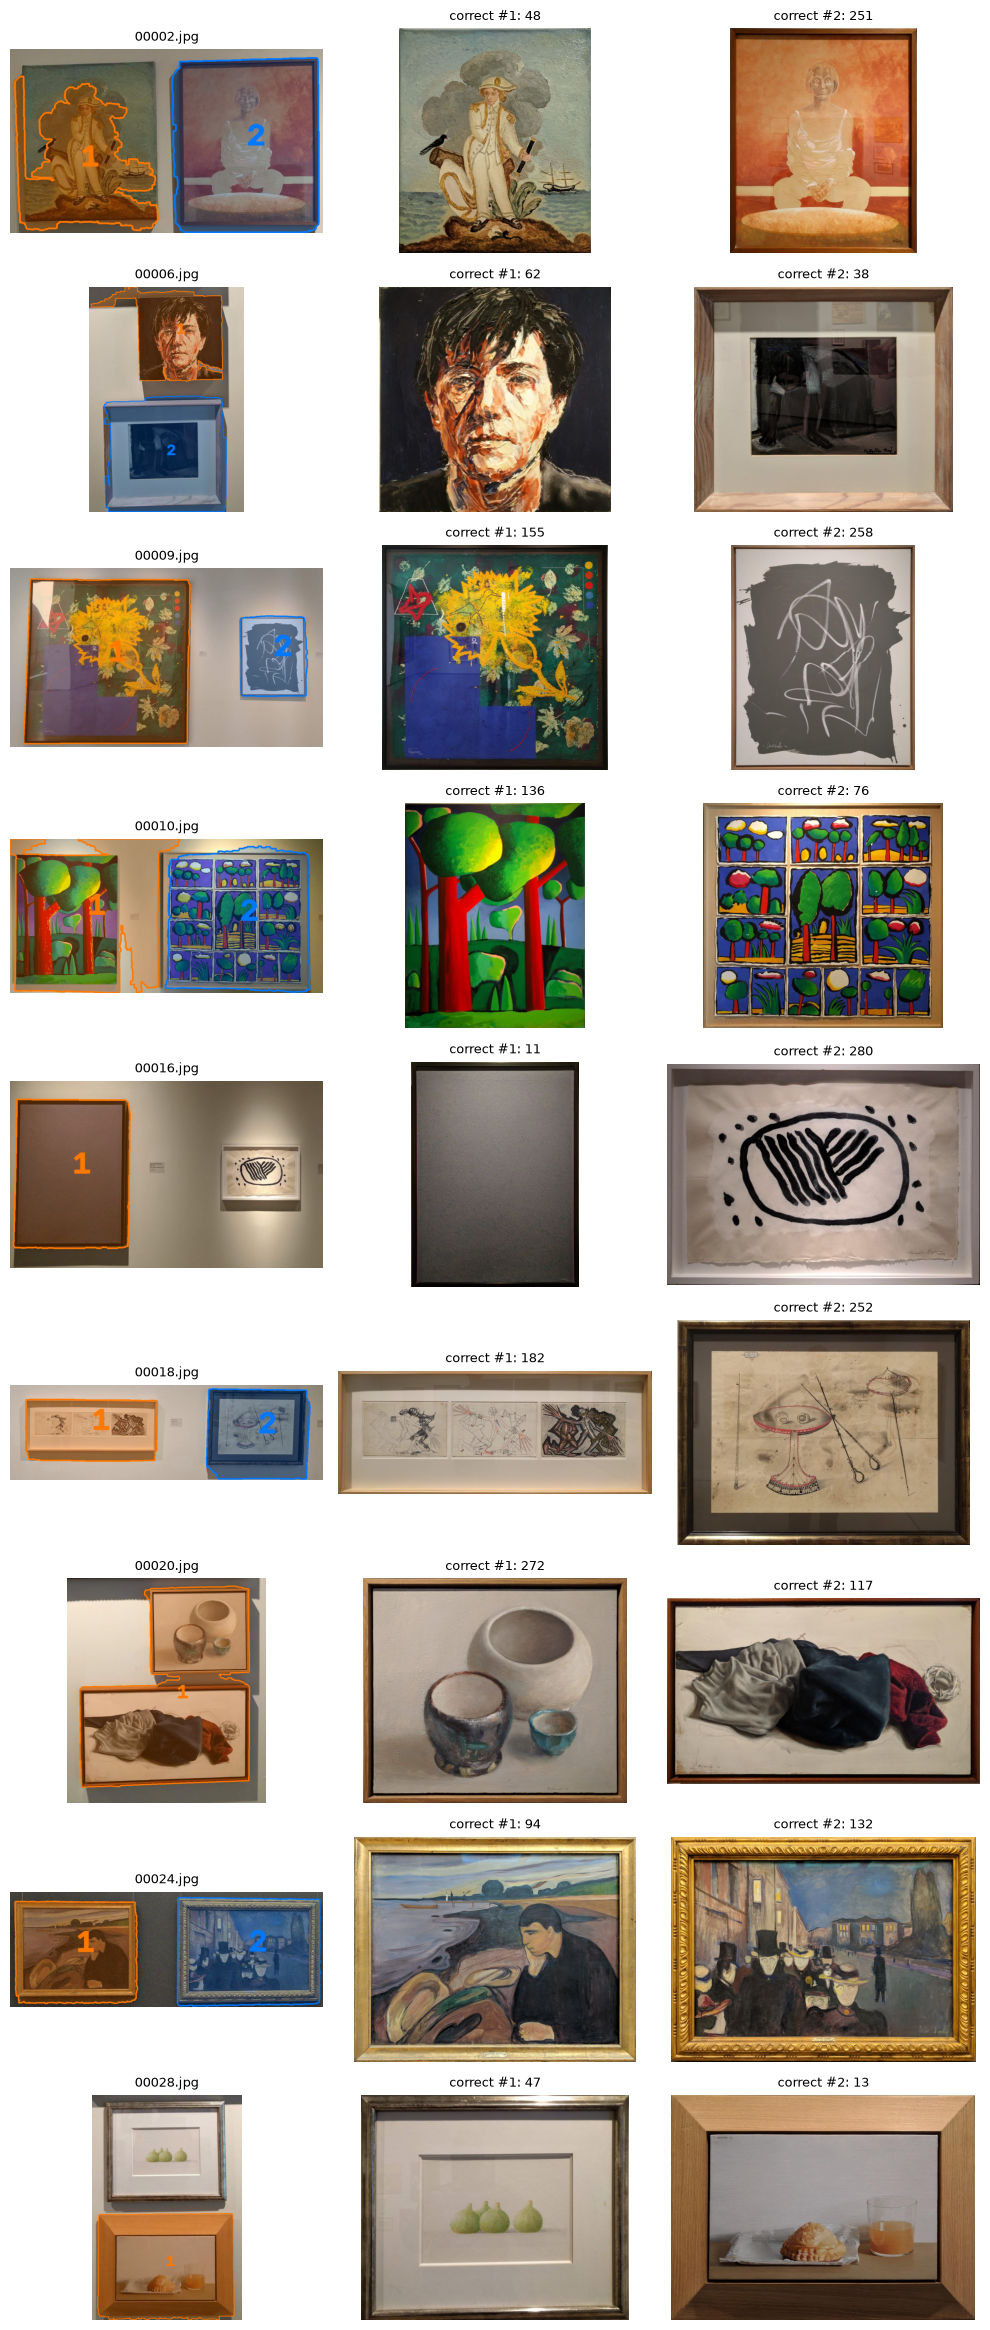

In [20]:
two = [i for i, g in enumerate(qsd1_gt) if len(g) >= 2]
fig, axes = plt.subplots(len(two), 3, figsize=(10, 2.6 * len(two)), squeeze=False)
for row, i in enumerate(two):
    axes[row, 0].imshow(draw_regions(qsd1_imgs[i], qsd1_regions[i]))
    axes[row, 0].set_title(qsd1_files[i], fontsize=9)
    for col, b in enumerate(qsd1_gt[i][:2]):
        ax = axes[row, col + 1]
        if b == -1:
            ax.text(0.5, 0.5, "not in the museum", ha="center", va="center", transform=ax.transAxes)
        else:
            ax.imshow(cv2.cvtColor(bbdd_imgs[bbdd_index[b]], cv2.COLOR_BGR2RGB))
        ax.set_title(f"correct #{col + 1}: {b}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(results_dir, "pipeline_gt_order.png"), dpi=90, bbox_inches="tight")
plt.show()

### Painting crops

Input of the local descriptors: `qsd1_crops[i]` is the list of painting crops (BGR, left to right) of photo `i`, cut from the denoised photo. The museum images are used as they are (`bbdd_imgs`). `preprocess()` runs the whole common pipeline on a new photo (used for QST1-W4).

In [21]:
def preprocess(img):
    #common pipeline for one photo -> (denoised photo, painting masks left to right, painting crops)
    den = denoise(img)
    regions = segment_paintings(den, **SEG_PARAMS)
    return den, regions, [bbox_crop(den, r) for r in regions]

qsd1_crops = [[bbox_crop(img, r) for r in regions] for img, regions in zip(qsd1_denoised, qsd1_regions)]
print("paintings per photo:", pd.Series([len(c) for c in qsd1_crops]).value_counts().sort_index().to_dict())
sizes = np.array([c.shape[:2] for cc in qsd1_crops for c in cc])
print(f"crop height {sizes[:, 0].min()}-{sizes[:, 0].max()} px, width {sizes[:, 1].min()}-{sizes[:, 1].max()} px")

paintings per photo: {1: 24, 2: 6}
crop height 198-3559 px, width 234-3505 px


### Output format and evaluation

Every local-descriptor method only has to provide a `score_fn(crop)` that returns **one score per BBDD image** (same order as `bbdd_ids`, higher = more similar, e.g. the number of good matches). `predict_paintings()` turns the scores into the output format:

- top-10 BBDD ids (integers) of every painting, sorted by score;
- `[-1]` if the best score is below `min_score` (painting not in the museum); `min_score=None` never returns `[-1]`.

Evaluation:

- **map@k** (copied from Week 3): one AP per painting, comparing the i-th correct painting with the i-th detected one (a painting that is not detected counts as 0). An unknown painting counts as correct only if its prediction is `[-1]`.
- **F1 of the unknown detection**: positive class = painting not in the museum (correct answer `-1`), to choose the threshold on the number of matches.

In [22]:
UNKNOWN = -1
K = 10

def apk(actual, predicted, k=10):
    #average precision at k for one query (actual = list of correct bbdd ids)
    predicted = list(predicted)[:k]
    score, hits = 0.0, 0
    for i, p in enumerate(predicted):
        if p in actual and p not in predicted[:i]:
            hits += 1
            score += hits / (i + 1)
    return score / min(len(actual), k) if actual else 0.0

def mapk(actual, predicted, k=10):
    return np.mean([apk(a, p, k) for a, p in zip(actual, predicted)])

def painting_mapk(actual, predicted, k=10):
    #actual / predicted: for every photo, one entry per painting
    aps = []
    for a_img, p_img in zip(actual, predicted):
        for j, a in enumerate(a_img):
            aps.append(apk([a], p_img[j], k) if j < len(p_img) else 0.0)
    return np.mean(aps)

def unknown_f1(actual, predicted):
    #precision / recall / F1 of the unknown detection, painting by painting (positive = not in the museum)
    tp = fp = fn = 0
    for a_img, p_img in zip(actual, predicted):
        for j in range(max(len(a_img), len(p_img))):
            is_unk = j < len(a_img) and a_img[j] == UNKNOWN
            said_unk = j < len(p_img) and list(p_img[j]) == [UNKNOWN]
            tp += is_unk and said_unk
            fp += said_unk and not is_unk
            fn += is_unk and not said_unk
    p, r = tp / (tp + fp + EPS), tp / (tp + fn + EPS)
    return p, r, 2 * p * r / (p + r + EPS)

def rank_to_output(scores, min_score=None, k=K):
    #scores: one value per BBDD image (higher = more similar) -> k integer bbdd ids, or [-1] if unknown
    scores = np.asarray(scores, dtype=np.float64)
    if min_score is not None and scores.max() < min_score:
        return [UNKNOWN]
    return [int(b) for b in bbdd_ids[np.argsort(-scores, kind="stable")[:k]]]

def predict_paintings(crops, score_fn, min_score=None, k=K):
    #crops: for every photo, its painting crops -> for every photo, one output list per painting
    return [[rank_to_output(score_fn(c), min_score, k) for c in cc] for cc in crops]

def check_submission(preds, n_photos, k=K):
    assert len(preds) == n_photos, "one entry per photo"
    for photo in preds:
        assert len(photo) >= 1, "at least one painting per photo"
        for painting in photo:
            assert painting == [UNKNOWN] or (len(painting) == min(k, len(bbdd_ids)) and all(type(i) is int for i in painting)), \
                "k integer ids per painting, or [-1]"

In [23]:
#sanity checks of the format and the metrics (slides 10-11 examples)
assert apk([UNKNOWN], [UNKNOWN]) == 1.0 #unknown painting answered with [-1]: correct
assert apk([UNKNOWN], [2, 7, 9]) == 0.0 #unknown painting answered with ids: wrong
assert apk([2], [UNKNOWN]) == 0.0 #known painting answered with [-1]: wrong
assert unknown_f1([[UNKNOWN, 2]], [[[UNKNOWN], [2, 7]]])[2] > 0.99

#reference baselines on QSD1-W4: random scores, and answering [-1] for every painting
rng = np.random.default_rng(0)
random_preds = predict_paintings(qsd1_crops, lambda crop: rng.random(len(bbdd_ids)))
all_unknown = [[[UNKNOWN] for _ in cc] for cc in qsd1_crops]
check_submission(random_preds, len(qsd1_files))
check_submission(all_unknown, len(qsd1_files))
display(pd.DataFrame([
    {"method": "random scores", "map@1": painting_mapk(qsd1_gt, random_preds, 1), "map@5": painting_mapk(qsd1_gt, random_preds, 5)},
    {"method": "always [-1]", "map@1": painting_mapk(qsd1_gt, all_unknown, 1), "map@5": painting_mapk(qsd1_gt, all_unknown, 5)},
]).round(4))

,method,map@1,map@5
0,random scores,0.0000,0.0000
1,always [-1],0.2564,0.2564


## TASK 1 & 2: Keypoints, local descriptors and matching

All the methods use the same input (`qsd1_crops`, `bbdd_imgs`) and the same output (`score_fn` → `predict_paintings`), so they can be compared directly.

### SIFT

DoG keypoint detector + SIFT descriptor. Matching with L2 distance + Lowe's ratio test (1st / 2nd best match). Score of a BBDD image = number of matches that pass the test.

### ORB

FAST keypoints + BRIEF binary descriptor. Matching with Hamming distance + bidirectional matching (`crossCheck`).

### Third descriptor

### Comparison of the descriptors

Speed, number of keypoints, robustness to noise and colour changes.

### Similarity metrics

L2 vs Hamming, ratio test vs cross-check.

### Unknown detection

Threshold on the number of matches (`min_score`), chosen by optimizing the F1 of the unknown detection on QSD1-W4.

## TASK 3: Evaluation on QSD1-W4 and comparison with the best Week 3 system

Best Week 3 system: denoising + painting detection + LBP 8x8 with radii 1, 2, 3 (P=8), L1 distance.

## TASK 4: Blind submission (QST1-W4)

Only the best method (`method1`), with `[-1]` for unknown paintings. Nothing is tuned on the test set.